# Mocap Observer Design

Custom observer for Milestone 2: the full 9-state model with mocap position and attitude as measurements, replacing the flow-deck and z-ranger observer from Lab 8. With the Lab 8 observer, p_x, p_y, and psi were unobservable and drifted 20-50 cm over a 75 s flight.

Run from `project/`. Data comes from `labs/lab08/`.

## 1. Set up the notebook

In [1]:
import json
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg

from ae483.tools import load_hardware_data, resample_data_drone
from ae483.mytools import sync_data_mocap

LAB08 = Path('../labs/lab08')
MODEL_FILE = LAB08 / 'model.json'
FLIGHT_FILE = LAB08 / 'lab08_squares_03.json'   # custom controller + Lab 8 observer, 5 squares, mocap on

# Recording used for mocap noise (Section 3). Until a dedicated still recording
# exists, the still period before takeoff in FLIGHT_FILE is used.
NOISE_FILE = FLIGHT_FILE

STATE_NAMES = ['p_x', 'p_y', 'p_z', 'psi', 'theta', 'phi', 'v_x', 'v_y', 'v_z']
INPUT_NAMES = ['w_x', 'w_y', 'w_z', 'a_z']
MEAS_NAMES = ['p_x', 'p_y', 'p_z', 'psi', 'theta', 'phi']

np.set_printoptions(precision=4, suppress=True, linewidth=150)

In [3]:
def lqr(A, B, Q, R):
    P = linalg.solve_continuous_are(A, B, Q, R)
    K = linalg.inv(R) @ B.T @ P
    return K


def obsv(A, C):
    return np.vstack([C @ np.linalg.matrix_power(A, i) for i in range(A.shape[0])])


def wrap(angle):
    # Wrap an angle (or array of angles) to [-pi, pi)
    return (angle + np.pi) % (2 * np.pi) - np.pi


def rmse(x):
    x = x[~np.isnan(x)]
    return np.sqrt(np.mean(x**2))

## 2. Model and observability

- `A` (9x9) and `B` (9x4) are the Lab 8 linearized model, with all 9 states kept
- `C` = first 6 rows of the 9x9 identity, so the measurements are p_x, p_y, p_z, psi, theta, phi from mocap; `D` = 0

In [4]:
with open(MODEL_FILE, 'r') as f:
    model = json.load(f)

A = np.array(model['A'])
B = np.array(model['B'])
g = model['g']

C = np.eye(9)[:6]
D = np.zeros((6, 4))

C_lab08 = np.array(model['C'])   # flow (n_x, n_y) + z-ranger (r), for comparison

print(f'A =\n{A}\n')
print(f'B =\n{B}\n')
print(f'C =\n{C}\n')
print(f'rank W_o, Lab 8 sensors (flow + ranger): {np.linalg.matrix_rank(obsv(A, C_lab08))} of {A.shape[0]}')
print(f'rank W_o, mocap position + attitude:     {np.linalg.matrix_rank(obsv(A, C))} of {A.shape[0]}')

A =
[[ 0.    0.    0.    0.    0.    0.    1.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    1.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    0.    1.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    9.81  0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.   -9.81  0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    0.    0.  ]]

B =
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 1.]]

C =
[[1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0.]]

rank W_o, Lab 8 sensors (flow + ranger): 6 of 9
rank W_o, mocap position + attitude:     9 of 9


## 3. Measurement noise from mocap

Variance of mocap x, y, z, yaw, pitch, and roll while the drone sits still with the motors off. The still period is the stretch at the start of the recording before z moves by more than 5 mm.

Replace `NOISE_FILE` with a dedicated recording of about 30 s when you have one. Noise in flight will be somewhat higher because of vibration.

In [5]:
_, raw_noise_mocap, _ = load_hardware_data(NOISE_FILE)

z_raw = np.array(raw_noise_mocap['z'], dtype=float)
t_raw = np.array(raw_noise_mocap['time'], dtype=float)
moved = np.flatnonzero(np.abs(z_raw - z_raw[0]) > 0.005)
n_still = moved[0] if len(moved) > 0 else len(z_raw)
print(f'Still period: {n_still} samples, {t_raw[n_still - 1] - t_raw[0]:.2f} s')
print(f'Mocap rate: {1 / np.median(np.diff(t_raw)):.0f} Hz\n')

meas_var = np.empty(6)
for j, key in enumerate(['x', 'y', 'z', 'yaw', 'pitch', 'roll']):
    s = np.array(raw_noise_mocap[key][:n_still], dtype=float)
    s = s[~np.isnan(s)]
    if key in ['yaw', 'pitch', 'roll']:
        s = np.unwrap(s)
    meas_var[j] = np.var(s)
    print(f'{MEAS_NAMES[j]:>6}: std = {np.sqrt(meas_var[j]):.2e}, var = {meas_var[j]:.2e}')

Still period: 346 samples, 3.45 s
Mocap rate: 100 Hz

   p_x: std = 6.83e-05, var = 4.66e-09
   p_y: std = 4.97e-05, var = 2.47e-09
   p_z: std = 3.35e-04, var = 1.12e-07
   psi: std = 1.42e-03, var = 2.01e-06
 theta: std = 1.62e-03, var = 2.64e-06
   phi: std = 1.15e-03, var = 1.32e-06


## 4. Model error

Variances for p_z, theta, phi, v_x, v_y, and v_z are from the Lab 7 model-error analysis. p_x and p_y have the same model as p_z (p dot = v), so they start with the same value; psi starts with the theta value. Adjust these if the offline replay in Section 6 shows a state that tracks poorly.

In [16]:
model_var = np.array([
    3.36e-3,   # p_x   (same as p_z)
    3.36e-3,   # p_y   (same as p_z)
    3.36e-3,   # p_z
    3.61e-4,   # psi   (same as theta)
    3.61e-4,   # theta
    8.41e-4,   # phi
    4.33e-2,   # v_x
    5.11e-2,   # v_y
    1.27e-1,   # v_z
])
for name, v in zip(STATE_NAMES, model_var):
    print(f'{name:>6}: var = {v:.2e}')

   p_x: var = 3.36e-03
   p_y: var = 3.36e-03
   p_z: var = 3.36e-03
   psi: var = 3.61e-04
 theta: var = 3.61e-04
   phi: var = 8.41e-04
   v_x: var = 4.33e-02
   v_y: var = 5.11e-02
   v_z: var = 1.27e-01


## 5. Observer gain L and eigenvalue check

L is the dual LQR solution with weights equal to 1 / variance, as in Lab 7 and 8. Measurement noise from mocap is tiny, so with the measured variances the observer trusts mocap almost completely and its eigenvalues are very fast. That breaks in two ways:

- Forward Euler at the firmware rate (dt = 0.002 s) goes unstable once |1 + lambda dt| > 1, i.e. for eigenvalues faster than about -1000 rad/s
- Mocap arrives over the radio about 10-20 ms late, so the observer cannot usefully respond much faster than a few tens of rad/s

So the measurement variances are inflated by one common factor until the fastest eigenvalue is no faster than `max_rate`. Report this factor in the paper alongside the measured variances.

In [17]:
def design_L(meas_scale):
    return lqr(A.T, C.T, np.diag(model_var), np.diag(meas_var * meas_scale)).T


def fastest(L):
    return np.max(-np.linalg.eigvals(A - L @ C).real)


L_raw = design_L(1.)
print('Eigenvalues of A - L C with the measured variances:')
print(np.sort(np.linalg.eigvals(A - L_raw @ C).real), '\n')

max_rate = 30.   # rad/s, fastest allowed observer eigenvalue
scales = np.logspace(0, 12, 1201)
ok = [s for s in scales if fastest(design_L(s)) <= max_rate]
meas_scale = ok[0] if ok else scales[-1]
L = design_L(meas_scale)
eigs = np.linalg.eigvals(A - L @ C)

print(f'Measurement-variance inflation factor: {meas_scale:.3g}')
print(f'(measurement std multiplied by {np.sqrt(meas_scale):.3g})\n')
print('Eigenvalues of A - L C:')
print(np.sort(eigs.real))
print(f'\nAll stable: {np.all(eigs.real < 0)}')
for dt_check in [0.002, 0.01]:
    print(f'Forward Euler stable at dt = {dt_check}: {np.all(np.abs(1 + eigs * dt_check) < 1)}')

Eigenvalues of A - L C with the measured variances:
[-1165.2853  -848.9212  -173.1189   -25.2544   -13.4089   -11.6967    -6.1519    -3.9048    -3.6015] 

Measurement-variance inflation factor: 1.51e+03
(measurement std multiplied by 38.9)

Eigenvalues of A - L C:
[-29.6936 -21.5155  -4.3179  -4.3179  -3.6856  -3.5165  -1.5114  -0.9783  -0.3447]

All stable: True
Forward Euler stable at dt = 0.002: True
Forward Euler stable at dt = 0.01: True


In [18]:
print('L (rows = states, columns = p_x, p_y, p_z, psi, theta, phi errors):')
for name, row in zip(STATE_NAMES, L):
    print(f'{name:>6}: {row}')

L (rows = states, columns = p_x, p_y, p_z, psi, theta, phi errors):
   p_x: [25.8915  0.      0.     -0.      0.0116  0.    ]
   p_y: [ 0.     34.5156  0.      0.      0.     -0.023 ]
   p_z: [0.     0.     8.6357 0.     0.     0.    ]
   psi: [-0.      0.      0.      0.3447  0.      0.    ]
 theta: [6.5716 0.     0.     0.     0.1187 0.    ]
   phi: [  0.     -12.2307   0.       0.       0.       0.3751]
   v_x: [97.1497  0.      0.      0.      0.3022  0.    ]
   v_y: [  0.     147.2248   0.       0.       0.      -0.8008]
   v_z: [ 0.      0.     27.3748  0.      0.      0.    ]


## 6. Offline replay on `lab08_squares_03.json`

The replay uses the same update equations the firmware will use:

- Prediction: p dot = v, psi dot = w_z, theta dot = w_y, phi dot = w_x, v_x dot = g theta, v_y dot = -g phi, v_z dot = a_z - g
- Correction: subtract L (C x - y) whenever a mocap measurement is available, holding the last one between arrivals
- If no new mocap arrives for `stale_after` seconds (or it is NaN), predict only

To make it realistic, mocap is delayed by `mocap_delay` and held at `mocap_rate_hz`. Change `mocap_rate_hz` to the rate the drone actually receives once the firmware logs it. The replay runs at the log rate (dt = 0.01 s), not the firmware's 0.002 s.

Mocap here is synced and transformed into the drone's starting frame, which is what lets it be compared with the logged estimates. On the drone, mocap arrives in the room's frame instead.

In [19]:
raw_data_drone, raw_data_mocap, _ = load_hardware_data(FLIGHT_FILE)
data_drone = resample_data_drone(raw_data_drone, t_min_offset=0., t_max_offset=0.)
data_mocap = sync_data_mocap(
    raw_data_mocap,
    data_drone['time'],
    data_drone['ae483log.p_z'],
    do_transform=True,
    t_min_offset=0.,
    t_shift_rng=1.,
    t_shift_res=0.05,
)

t = data_drone['time']
dt = t[1] - t[0]
u_log = np.column_stack([data_drone[f'ae483log.{k}'] for k in INPUT_NAMES])
y_mocap = np.column_stack([data_mocap[k] for k in ['x', 'y', 'z', 'yaw', 'pitch', 'roll']])
x_lab08 = np.column_stack([data_drone[f'ae483log.{k}'] for k in STATE_NAMES])
flying = data_drone['ae483log.p_z_des'] > 0.05

print(f'dt = {dt:.3f} s, {len(t)} samples, {flying.sum() * dt:.1f} s in flight')
print(f'NaN mocap samples: {np.isnan(y_mocap).any(axis=1).sum()}')

dt = 0.010 s, 8515 samples, 78.5 s in flight
NaN mocap samples: 0


In [20]:
def run_observer(L, t, u, y, mocap_delay=0.015, mocap_rate_hz=100., stale_after=0.2):
    dt = t[1] - t[0]
    n_delay = int(round(mocap_delay / dt))
    n_hold = max(1, int(round(1 / (mocap_rate_hz * dt))))

    # Initialize position and attitude from the first valid mocap sample, velocity at zero
    i0 = np.flatnonzero(~np.isnan(y).any(axis=1))[0]
    x = np.concatenate([y[i0], np.zeros(3)])

    x_hat = np.full((len(t), 9), np.nan)
    y_held = None
    t_held = -np.inf
    for i in range(len(t)):
        # A new mocap sample arrives every n_hold steps, n_delay steps late
        j = i - n_delay
        if j >= 0 and i % n_hold == 0 and not np.isnan(y[j]).any():
            y_held = y[j]
            t_held = t[i]

        p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z = x
        w_x, w_y, w_z, a_z = u[i]
        x_dot = np.array([v_x, v_y, v_z, w_z, w_y, w_x, g * theta, -g * phi, a_z - g])

        if y_held is not None and t[i] - t_held <= stale_after:
            err = C @ x - y_held
            err[3] = wrap(err[3])   # yaw error
            x_dot -= L @ err

        x = x + dt * x_dot
        x_hat[i] = x
    return x_hat


x_mocap_obs = run_observer(L, t, u_log, y_mocap)

In [21]:
# Velocity from mocap: central difference, light smoothing, rotated into the body frame by yaw
v_world = np.gradient(y_mocap[:, :3], dt, axis=0)
kernel = np.ones(5) / 5
v_world = np.column_stack([np.convolve(v_world[:, k], kernel, mode='same') for k in range(3)])
psi_m = y_mocap[:, 3]
v_mocap = np.column_stack([
     np.cos(psi_m) * v_world[:, 0] + np.sin(psi_m) * v_world[:, 1],
    -np.sin(psi_m) * v_world[:, 0] + np.cos(psi_m) * v_world[:, 1],
    v_world[:, 2],
])
truth = np.column_stack([y_mocap, v_mocap])


def error_table(x_hat):
    err = x_hat[flying] - truth[flying]
    err[:, 3] = wrap(err[:, 3])
    return err


err_mocap_obs = error_table(x_mocap_obs)
err_lab08 = error_table(x_lab08)
print(f'RMSE in flight (estimate - mocap)   {"mocap observer":>15} {"Lab 8 observer":>15}')
for k, name in enumerate(STATE_NAMES):
    print(f'{name:>34}  {rmse(err_mocap_obs[:, k]):15.4f} {rmse(err_lab08[:, k]):15.4f}')

xy_mocap_obs = np.hypot(err_mocap_obs[:, 0], err_mocap_obs[:, 1])
xy_lab08 = np.hypot(err_lab08[:, 0], err_lab08[:, 1])
print(f'\nmax horizontal error: mocap observer {np.nanmax(xy_mocap_obs) * 100:.1f} cm, '
      f'Lab 8 observer {np.nanmax(xy_lab08) * 100:.1f} cm')

RMSE in flight (estimate - mocap)    mocap observer  Lab 8 observer
                               p_x           0.0013          0.2060
                               p_y           0.0012          0.2388
                               p_z           0.0061          0.0245
                               psi           0.0169          0.0408
                             theta           0.0233          0.0224
                               phi           0.0227          0.0211
                               v_x           0.0303          0.0656
                               v_y           0.0316          0.0641
                               v_z           0.0628          0.0605

max horizontal error: mocap observer 1.1 cm, Lab 8 observer 61.8 cm


Position, attitude, and velocity estimates against mocap.

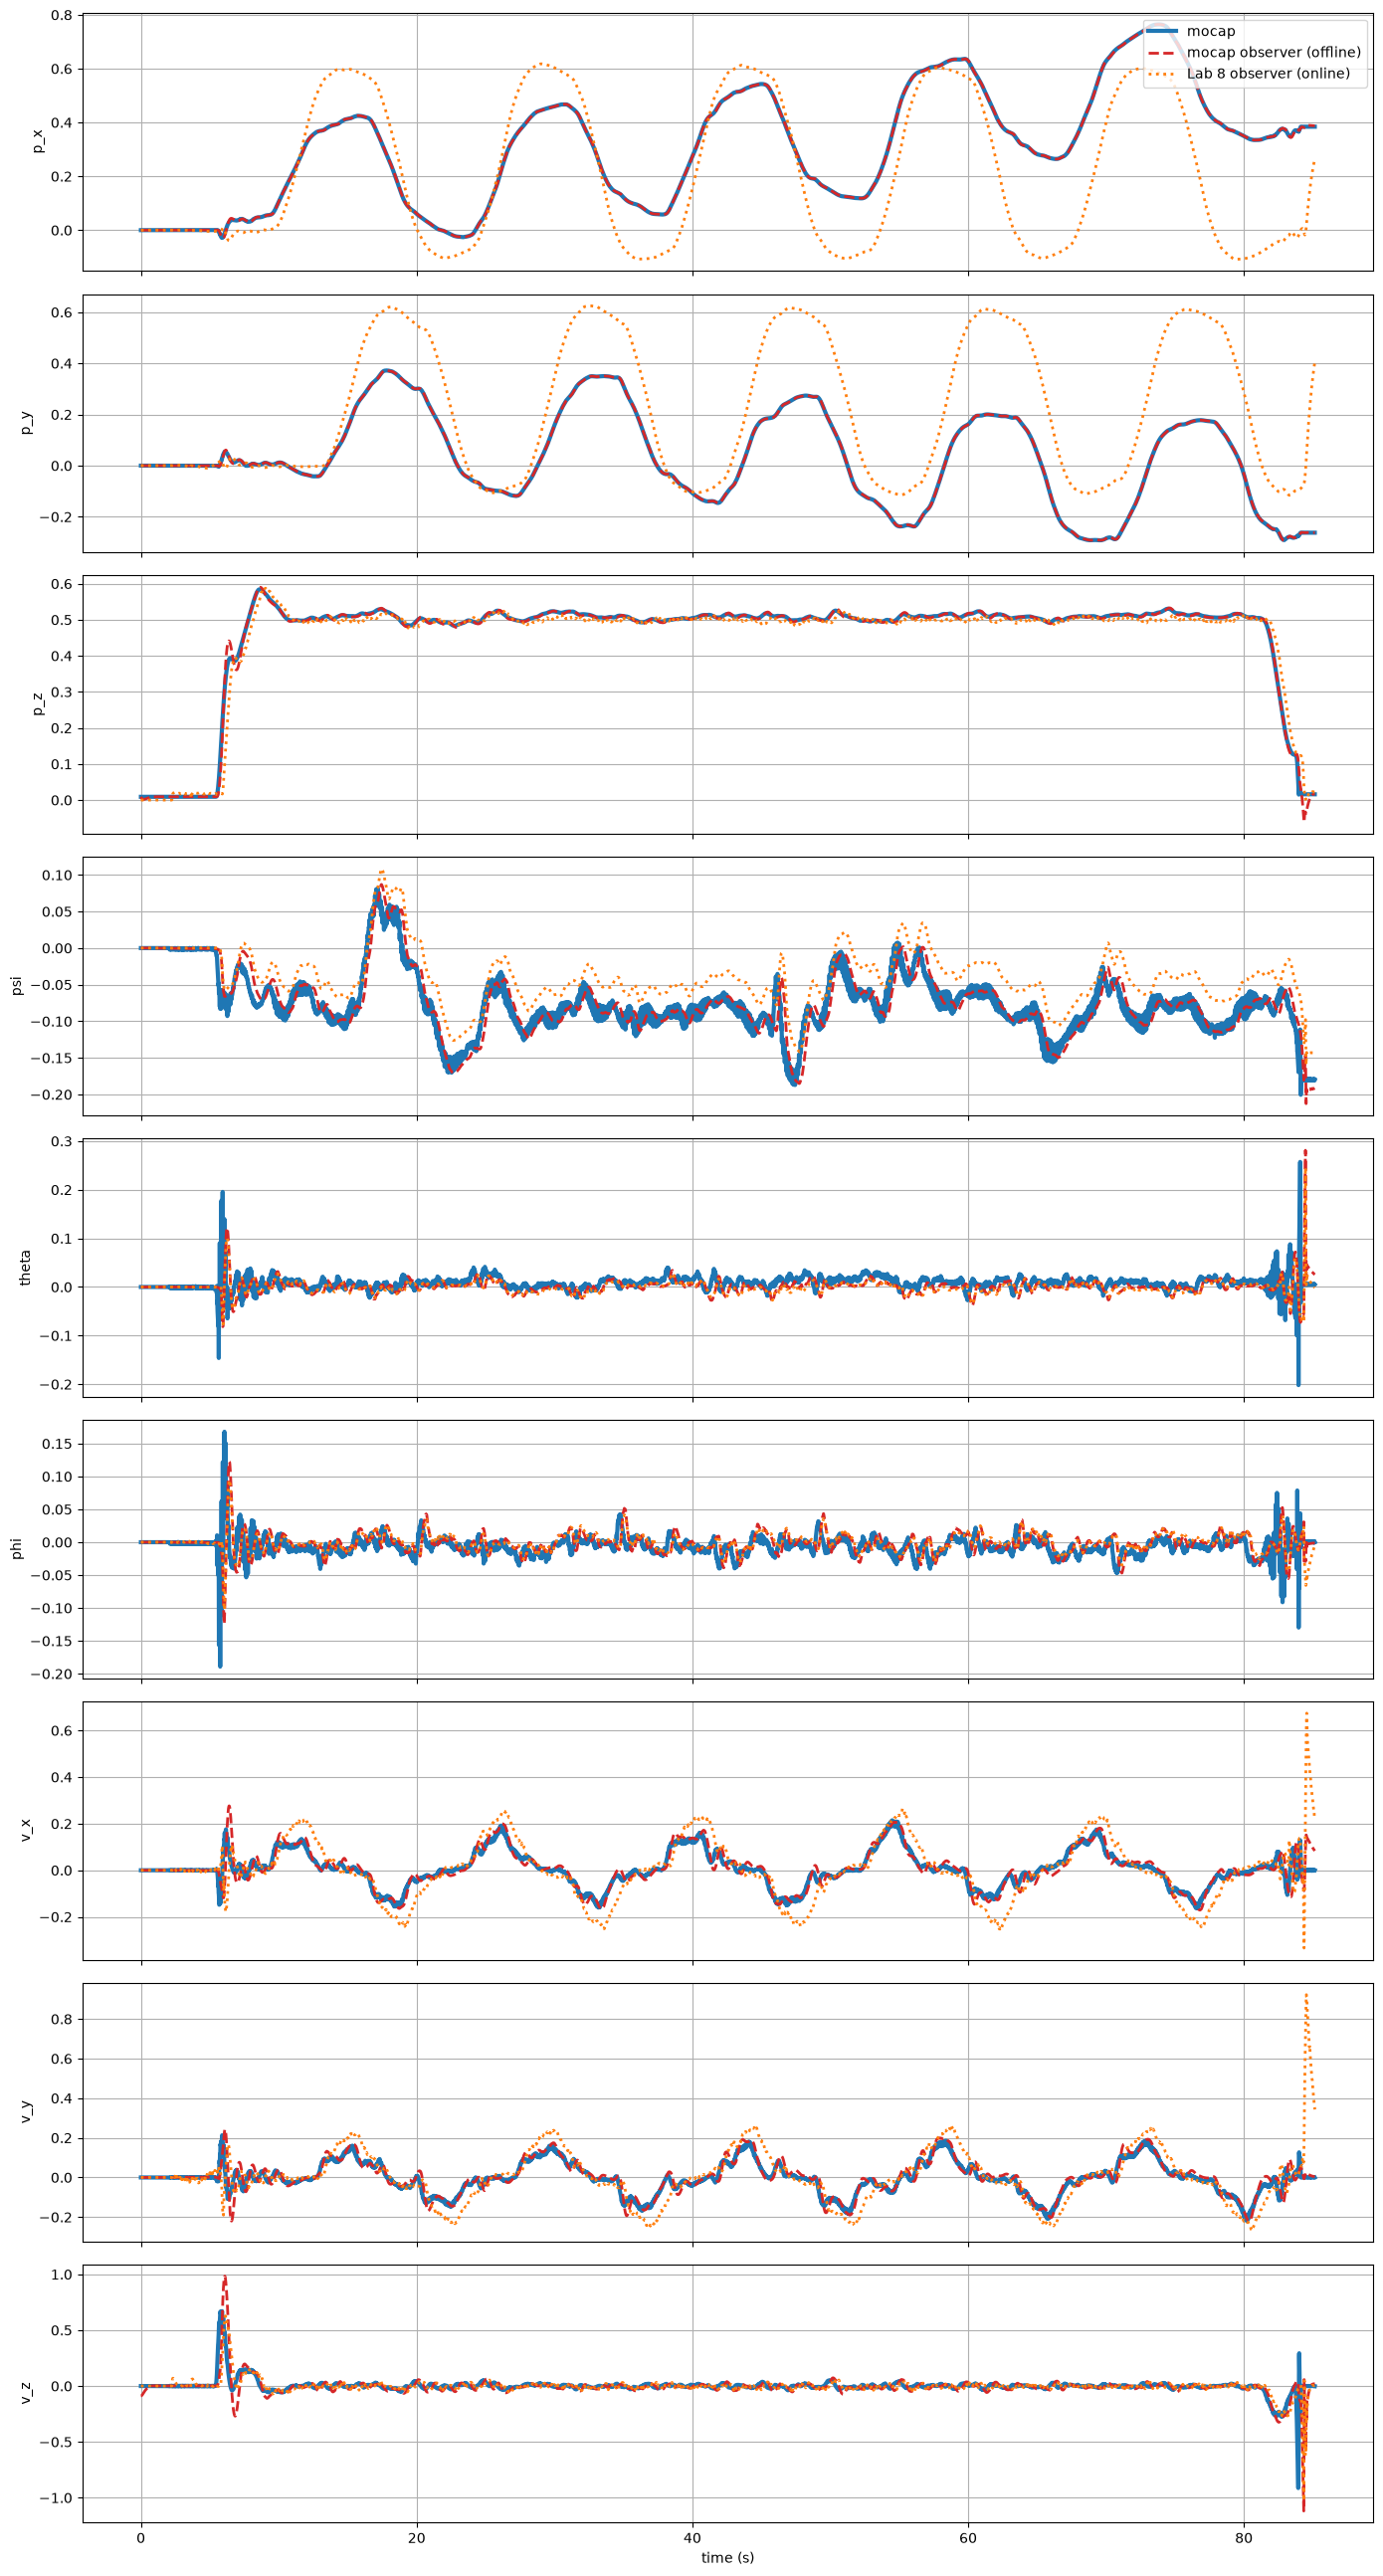

In [22]:
fig, axes = plt.subplots(9, 1, figsize=(14, 26), sharex=True)
for k, (ax, name) in enumerate(zip(axes, STATE_NAMES)):
    ax.plot(t, truth[:, k], label='mocap', linewidth=3, color='C0')
    ax.plot(t, x_mocap_obs[:, k], '--', label='mocap observer (offline)', linewidth=2, color='C3')
    ax.plot(t, x_lab08[:, k], ':', label='Lab 8 observer (online)', linewidth=2, color='C1')
    ax.set_ylabel(name)
    ax.grid()
axes[0].legend(loc='upper right')
axes[-1].set_xlabel('time (s)')
plt.tight_layout()
plt.show()

Horizontal position error over the flight. The Lab 8 observer drifts; the mocap observer should stay flat.

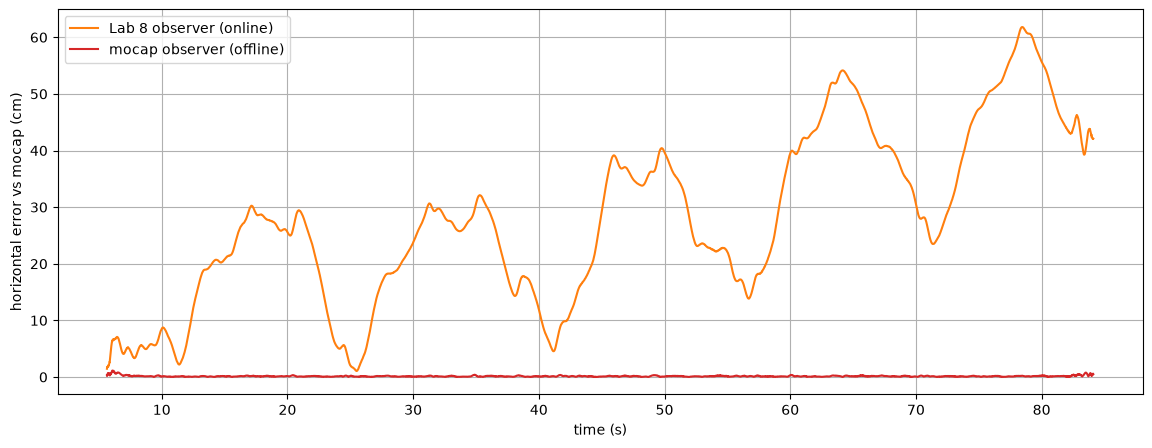

In [23]:
t_fly = t[flying]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(t_fly, xy_lab08 * 100, label='Lab 8 observer (online)', color='C1')
ax.plot(t_fly, xy_mocap_obs * 100, label='mocap observer (offline)', color='C3')
ax.set_xlabel('time (s)')
ax.set_ylabel('horizontal error vs mocap (cm)')
ax.grid()
ax.legend()
plt.show()

Sensitivity to mocap delay and rate. The firmware will see whatever the radio delivers, so the observer should not get much worse across this range. Delays are rounded to the 0.01 s log step.

In [14]:
print(f'{"delay (s)":>10} {"rate (Hz)":>10} {"p xy RMSE (cm)":>15} {"v xy RMSE (m/s)":>16}')
for delay in [0., 0.02, 0.04]:
    for rate in [100., 50.]:
        e = error_table(run_observer(L, t, u_log, y_mocap, mocap_delay=delay, mocap_rate_hz=rate))
        p_xy = rmse(np.hypot(e[:, 0], e[:, 1]))
        v_xy = rmse(np.hypot(e[:, 6], e[:, 7]))
        print(f'{delay:10.2f} {rate:10.0f} {p_xy * 100:15.2f} {v_xy:16.3f}')

 delay (s)  rate (Hz)  p xy RMSE (cm)  v xy RMSE (m/s)
      0.00        100            0.19            0.042
      0.00         50            0.16            0.043
      0.02        100            0.18            0.044
      0.02         50            0.22            0.044
      0.04        100            0.36            0.045
      0.04         50            0.41            0.045


Position matching mocap is partly guaranteed, because mocap position is the measurement. The real test is velocity, which mocap does not measure directly: its RMSE should be close to or better than the Lab 8 observer's.

## 7. Export L for firmware

Prints L as a C array for `controller_ae483.c`, and saves L with the weights it came from to `observer_gains.json`. In the firmware, the 6 error terms are ordered p_x, p_y, p_z, psi, theta, phi, the same as the columns of L.

In [15]:
L_export = np.where(np.abs(L) < 1e-9, 0., L)   # drop round-off (entries ~1e-17)
rows = ',\n'.join('  {' + ', '.join(f'{v:.6e}f' for v in row) + '}' for row in L_export)
print(f'static float L[9][6] = {{\n{rows}\n}};')

with open('observer_gains.json', 'w') as f:
    json.dump({
        'created': datetime.now().isoformat(timespec='seconds'),
        'states': STATE_NAMES,
        'measurements': MEAS_NAMES,
        'L': L_export.tolist(),
        'meas_var': meas_var.tolist(),
        'meas_scale': meas_scale,
        'model_var': model_var.tolist(),
        'eigenvalues': np.sort(eigs.real).tolist(),
        'noise_file': str(NOISE_FILE),
    }, f, indent=2)
print('\nWrote observer_gains.json')

static float L[9][6] = {
  {2.589154e+01f, 0.000000e+00f, 0.000000e+00f, 0.000000e+00f, 1.161849e-02f, 0.000000e+00f},
  {0.000000e+00f, 3.451562e+01f, 0.000000e+00f, 0.000000e+00f, 0.000000e+00f, -2.295224e-02f},
  {0.000000e+00f, 0.000000e+00f, 8.635719e+00f, 0.000000e+00f, 0.000000e+00f, 0.000000e+00f},
  {0.000000e+00f, 0.000000e+00f, 0.000000e+00f, 3.446613e-01f, 0.000000e+00f, 0.000000e+00f},
  {6.571610e+00f, 0.000000e+00f, 0.000000e+00f, 0.000000e+00f, 1.187165e-01f, 0.000000e+00f},
  {0.000000e+00f, -1.223070e+01f, 0.000000e+00f, 0.000000e+00f, 0.000000e+00f, 3.750774e-01f},
  {9.714967e+01f, 0.000000e+00f, 0.000000e+00f, 0.000000e+00f, 3.021999e-01f, 0.000000e+00f},
  {0.000000e+00f, 1.472248e+02f, 0.000000e+00f, 0.000000e+00f, 0.000000e+00f, -8.008197e-01f},
  {0.000000e+00f, 0.000000e+00f, 2.737478e+01f, 0.000000e+00f, 0.000000e+00f, 0.000000e+00f}
};

Wrote observer_gains.json


## 8. On-drone tests

1. Bench test, motors off: move and tilt by hand, check that each estimate follows mocap with the right sign
2. 10 s hover
3. Repeat of the squares flight: the estimate should stay within 2-3 cm of mocap with no growth